# Credit Line Strategy: PD Model to Profit-Optimal Cutoffs

**Question:** which Lending Club applicants should a lender fund, and how much profit does a better risk model add?

Walkthrough of the full pipeline. All logic lives in `src/` and `sql/`; this notebook runs it and explains the results.

1. Data preparation in SQL
2. Champion model: WoE logistic scorecard
3. Challenger model: LightGBM, out-of-time validation
4. Strategy: profit by approval cutoff, champion vs challenger swap set
5. Monitoring: predicted vs actual defaults on the 2015 vintage

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

from run_pipeline import run
R = run()

raw_loans: 200,000 rows -> loans_model: 91,992 rows (lending_club.db)


dev 2007-2014: 50,175 loans, default 12.9% | OOT 2015: 41,817 loans, default 15.0%


             model  AUC_dev  AUC_2015  Gini_2015  KS_2015  score_PSI
 LC sub-grade only    0.647     0.685      0.370    0.270        NaN
Champion scorecard    0.668     0.685      0.370    0.276      0.009
    Challenger GBM    0.706     0.691      0.381    0.280      0.004
            ranker  approve_all_profit  devcut_approval  devcut_bad_rate  devcut_profit  hindsight_best_approval  hindsight_best_profit  profit_at_60pct  profit_at_70pct  profit_at_80pct  profit_at_90pct
            Random       3,717,764.548            0.999            0.150  3,700,008.569                    0.918          3,819,899.778    2,308,091.645    2,773,311.526    3,268,080.524    3,736,768.180
 LC sub-grade only       3,717,764.548            0.999            0.150  3,759,966.456                    0.771          5,655,498.544    4,688,429.982    5,317,475.157    5,527,668.228    5,311,099.635
Champion scorecard       3,717,764.548            0.987            0.147  4,000,051.351                    0.828

wrote tables to reports/ and charts to reports/figures/


## 1. Data preparation in SQL

`sql/features.sql` builds the modelling table from the raw extract: parses dates, converts employment length to years,
builds affordability ratios (payment-to-income, loan-to-income), and defines the population.

**Population:** 36-month individual loans issued 2007-2015, with a final outcome (Fully Paid / Charged Off).
Every loan in that window had reached maturity by the data snapshot. Later vintages only include loans that already
ended, which overstates their default rate, so they are excluded.

**Split:** develop on 2007-2014, validate on the 2015 vintage (out-of-time), the way a bank validates a model before deployment.

Portfolio view from `sql/portfolio_summary.sql`, 2015 vintage:

In [2]:
ps = pd.read_csv("../reports/portfolio_summary.csv")
ps[ps.issue_year == 2015].drop(columns="issue_year")

,grade,n_loans,default_rate,avg_int_rate,funded_musd,net_profit_musd,return_on_funded,lgd
8,A,10513,0.053,6.890,151.790,10.257,0.068,0.372
17,B,13497,0.119,10.030,169.180,12.349,0.073,0.374
26,C,11305,0.195,13.240,134.280,8.165,0.061,0.387
35,D,4804,0.274,16.650,58.890,2.517,0.043,0.414
44,E,1451,0.325,19.110,18.430,0.399,0.022,0.419
52,F,203,0.468,23.480,2.200,-0.135,-0.061,0.445
60,G,44,0.568,26.880,0.400,-0.052,-0.130,0.578


Note grades C-G in 2015: realized return on funded capital fell sharply versus earlier years. Rates were cut while defaults rose.
This shift drives the monitoring findings in section 5.

## 2. Champion: WoE logistic scorecard

Each feature is binned on the development sample (numeric bins forced to a monotonic bad rate, missing values in their own bin),
converted to Weight of Evidence, screened by Information Value, de-duplicated by correlation, and fit with logistic regression.
Features with a wrong-sign coefficient are removed.

Lending Club's sub-grade is treated like an external bureau score: it is available at decision time, and the question is whether
our application features add lift on top of it.

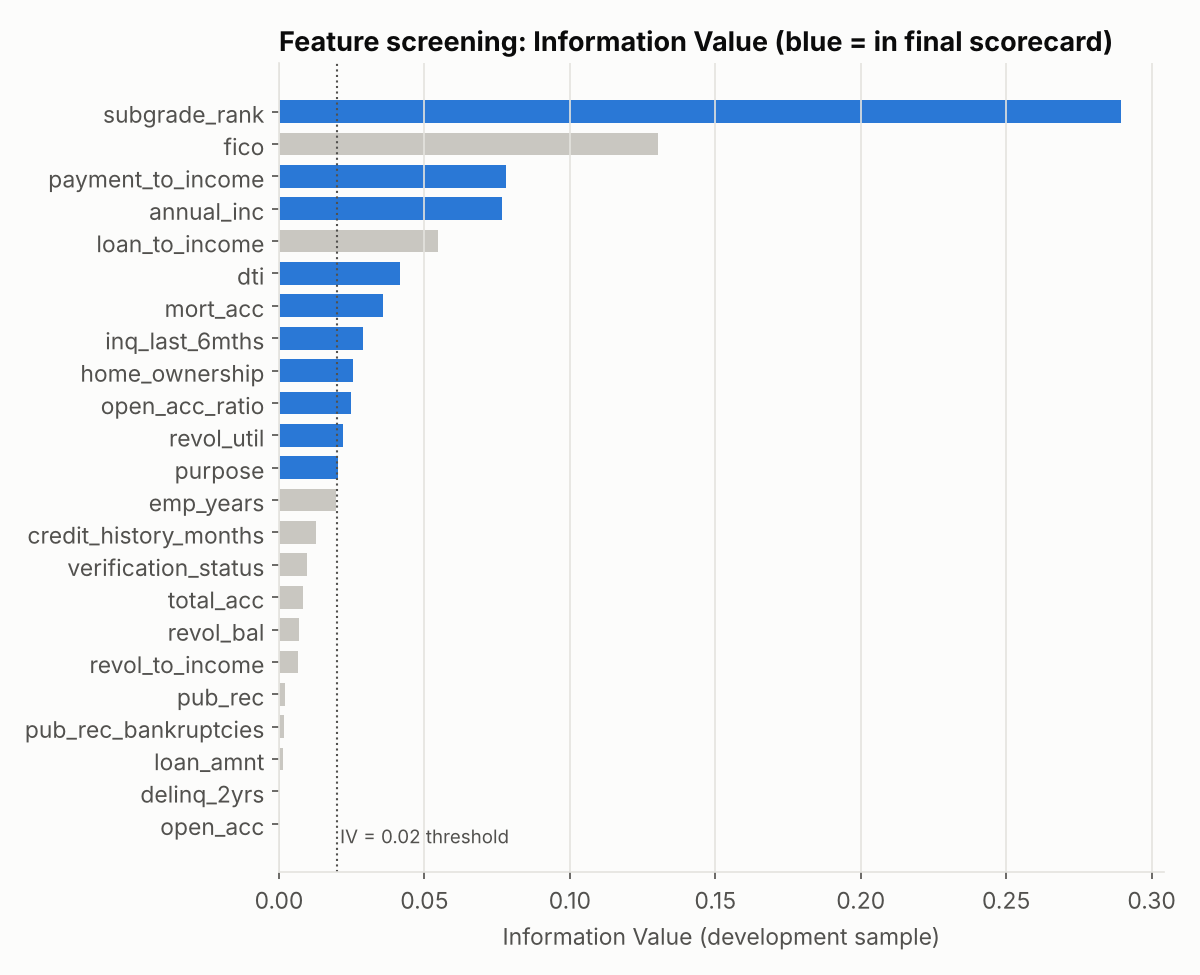

In [3]:
display(Image("../reports/figures/information_value.png", width=650))

In [4]:
pd.read_csv("../reports/features_dropped.csv")

,feature,reason
0,emp_years,IV < 0.02
1,credit_history_months,IV < 0.02
2,verification_status,IV < 0.02
3,total_acc,IV < 0.02
4,revol_bal,IV < 0.02
5,revol_to_income,IV < 0.02
6,pub_rec,IV < 0.02
7,pub_rec_bankruptcies,IV < 0.02
8,loan_amnt,IV < 0.02
9,delinq_2yrs,IV < 0.02


In [5]:
R['champ'].coefficients()

,feature,coef,iv
0,subgrade_rank,-0.814,0.290
1,payment_to_income,-0.567,0.078
2,annual_inc,-0.389,0.077
3,dti,-0.478,0.042
4,mort_acc,-0.156,0.036
5,inq_last_6mths,-0.589,0.029
6,home_ownership,-0.191,0.026
7,open_acc_ratio,-0.315,0.025
8,revol_util,-0.037,0.022
9,purpose,-0.380,0.020


Points table (score = sum of points; 600 points at 50:1 good:bad odds, 20 points to double the odds). Example features:

In [6]:
pts = R['champ'].points_table()
pts[pts.feature.isin(["payment_to_income", "inq_last_6mths"])]

,feature,bin,n,bad_rate,woe,points
21,inq_last_6mths,"[-inf, 1)",26188,0.112,0.156,56.900
22,inq_last_6mths,"[1, 2)",14116,0.136,-0.064,53.100
23,inq_last_6mths,"[2, inf)",9871,0.162,-0.270,49.700
36,payment_to_income,"[-inf, 0.03386)",7168,0.096,0.327,59.600
37,payment_to_income,"[0.03386, 0.04954)",7168,0.104,0.237,58.100
38,payment_to_income,"[0.04954, 0.06426)",7165,0.110,0.183,57.200
39,payment_to_income,"[0.06426, 0.08037)",7170,0.116,0.121,56.200
40,payment_to_income,"[0.08037, 0.1)",7168,0.127,0.012,54.400
41,payment_to_income,"[0.1, 0.129)",7168,0.149,-0.168,51.500
42,payment_to_income,"[0.129, inf)",7168,0.199,-0.520,45.700


## 3. Challenger and model validation

In [7]:
R['perf']

,model,AUC_dev,AUC_2015,Gini_2015,KS_2015,score_PSI
0,LC sub-grade only,0.647,0.685,0.370,0.270,NaN
1,Champion scorecard,0.668,0.685,0.370,0.276,0.009
2,Challenger GBM,0.706,0.691,0.381,0.280,0.004


- The scorecard matches the LC sub-grade on AUC and scores more stably between development and 2015 (score PSI under 0.01).
- The GBM challenger has the best 2015 discrimination (AUC 0.691) but a larger development-to-2015 drop, which is the usual trade-off of a more flexible model.
- AUC alone undersells the difference. What matters is profit at the cutoffs a lender would actually use (next section).

Champion decile table on 2015 (decile 1 = riskiest):

In [8]:
pd.read_csv("../reports/champion_deciles_2015.csv")

,decile,n,predicted_pd,actual_default,capture_of_bads
0,1,4182,0.272,0.308,0.205
1,2,4182,0.204,0.253,0.374
2,3,4181,0.170,0.209,0.513
3,4,4182,0.145,0.175,0.629
4,5,4182,0.124,0.153,0.731
5,6,4181,0.106,0.121,0.812
6,7,4182,0.088,0.103,0.880
7,8,4181,0.071,0.082,0.935
8,9,4182,0.053,0.063,0.977
9,10,4182,0.034,0.034,1.000


## 4. Strategy: profit by approval cutoff

Realized economic profit per loan = payments received net of the 1% servicing fee, minus collection fees, minus principal,
minus a funding cost (annual rate x principal x 1.5-year average life). Base case funding cost is 3%; results for 2% and 4% are in `reports/strategy_results.csv`.

Applicants are ranked by predicted PD and approved safest-first.

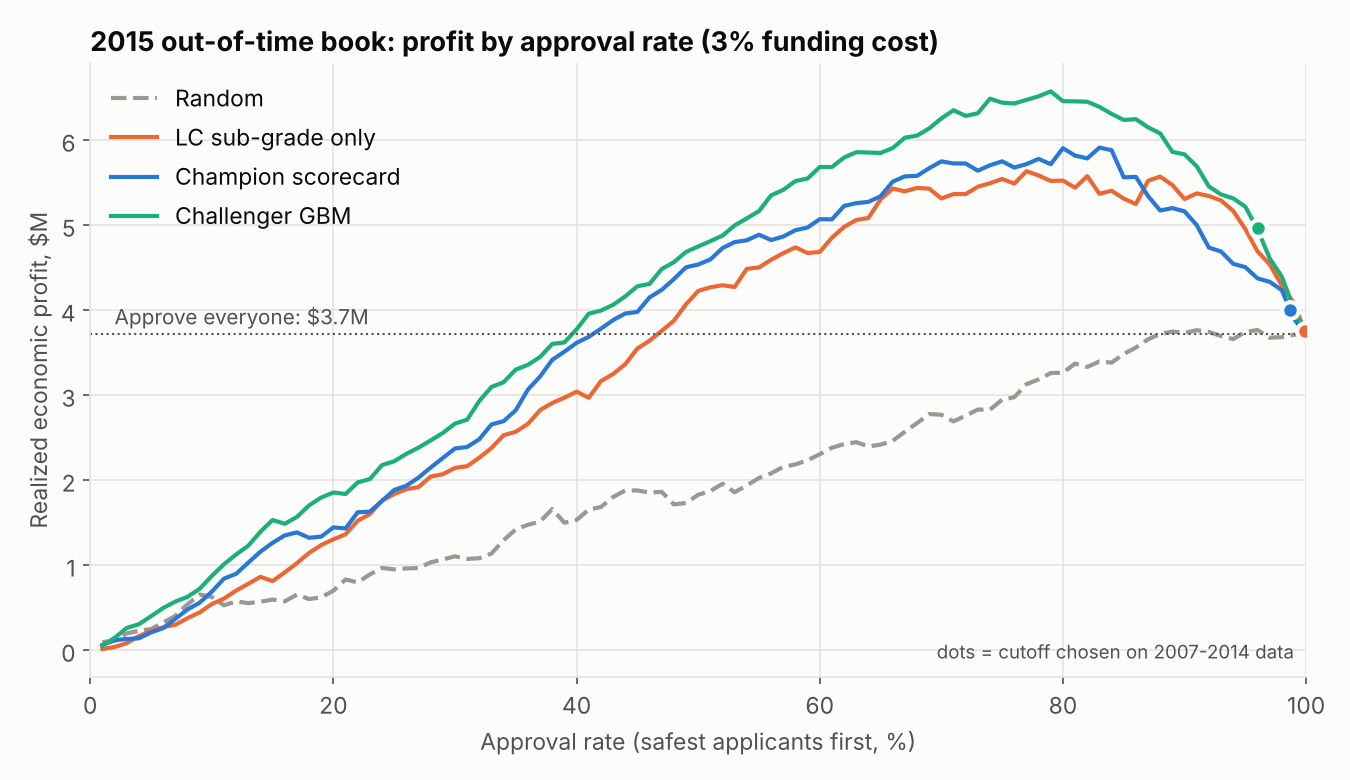

In [9]:
display(Image("../reports/figures/profit_curve.png", width=800))

In [10]:
s = R['strategy']
s3 = s[s.funding_rate == 0.03].set_index("ranker")
cols = ["approve_all_profit", "devcut_approval", "devcut_profit",
        "hindsight_best_approval", "hindsight_best_profit", "profit_at_80pct"]
out = s3[cols].copy()
for c in out.columns:
    if "profit" in c:
        out[c] = (out[c] / 1e6).round(2)
out.rename(columns=lambda c: c.replace("profit", "profit_$M"))

,approve_all_profit_$M,devcut_approval,devcut_profit_$M,hindsight_best_approval,hindsight_best_profit_$M,profit_$M_at_80pct
ranker,,,,,,
Random,3.720,0.999,3.700,0.918,3.820,3.270
LC sub-grade only,3.720,0.999,3.760,0.771,5.660,5.530
Champion scorecard,3.720,0.987,4.000,0.828,5.990,5.910
Challenger GBM,3.720,0.961,4.970,0.792,6.630,6.460


**Reading the results (3% funding cost):**
- Approving everyone earns $3.7M. Ranking by the challenger and approving about 80% earns $6.6M, about 1.8x more.
- At every approval rate, challenger > champion > LC sub-grade alone > random. Our features add value over the external grade.
- The cutoff learned on 2007-2014 data would have approved about 96-99% of 2015 applicants and captured only part of the gain.
  2015 was riskier than any development year, so a cutoff calibrated on benign history is too lenient.

### Champion vs challenger swap set (80% approval)

In [11]:
R['swap']

,segment,n,bad_rate,avg_int_rate,profit,profit_per_loan
0,Both approve,31736,0.111,9.893,"6,296,388.323",198.399
1,Swap-in (challenger only),1717,0.212,14.774,"165,342.138",96.297
2,Swap-out (champion only),1717,0.242,13.822,"-387,457.796",-225.660
3,Both decline,6647,0.298,16.252,"-2,356,508.117",-354.522


The two models agree on most decisions. Where they differ, the challenger's swap-ins default less (21% vs 24%) and earn more,
a net gain of about $0.55M. In practice this is the case for a controlled champion/challenger test (route a share of
applications to the challenger strategy) before full rollout.

## 5. Monitoring: expected vs actual

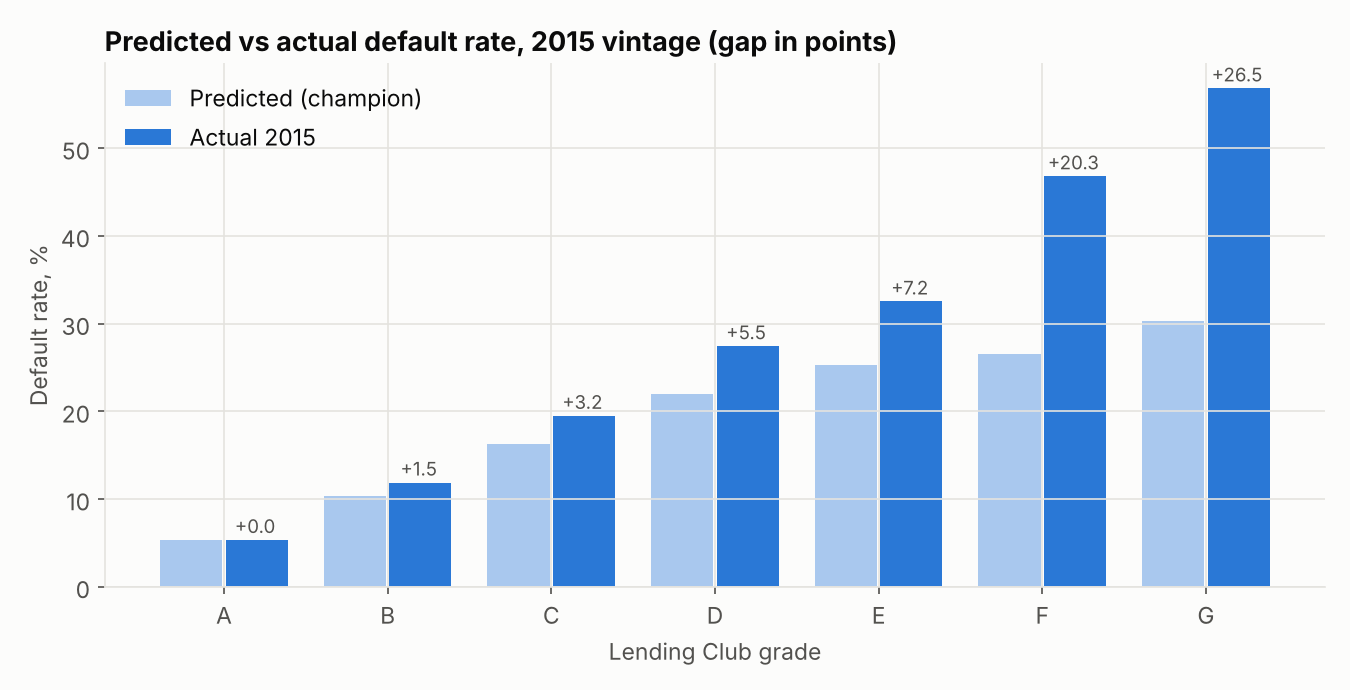

In [12]:
display(Image("../reports/figures/expected_vs_actual.png", width=800))

In [13]:
R['eva']

,grade,n,predicted_pd,actual_default,gap_pts
0,A,10513,0.053,0.053,0.031
1,B,13497,0.104,0.119,1.494
2,C,11305,0.163,0.195,3.174
3,D,4804,0.219,0.274,5.486
4,E,1451,0.253,0.325,7.222
5,F,203,0.265,0.468,20.273
6,G,44,0.303,0.568,26.541


The model ranks risk well in 2015, but its PD level is too low, and the gap widens with risk (B +1.5 pts, D +5.5 pts; F and G are thin samples).
This is calibration drift, not a ranking failure, and is the signal for action:

1. Recalibrate PD to the most recent vintages before setting cutoffs.
2. Tighten the cutoff in the C-E grades, where 2015 pricing no longer covered losses plus funding cost.
3. Track predicted vs actual default by vintage and score PSI monthly so drift is caught early, not after the vintage matures.

## Limitations
- Lending Club data only covers *approved* loans, so the models never see rejected applicants (reject inference not addressed).
- Funding cost and average life are simplifying assumptions; no discounting of cash flows.
- Profit is realized after the fact; a live strategy would also need forecasts of prepayment and loss severity.